# CLAM_TR v15: Level 1 (5x) Optimization

## Objective
Apply all Level 0 optimizations to Level 1 and test PANDA-exact configurations.

## Current Results
- **Level 0 (20x) Best**: 0.8832 QWK (F3_ConcatFusion with optimized HP)
- **Level 1 (5x) Best**: 0.7527 QWK (uni_clam_tr + P2_provider, DEFAULT HP)
- **Gap**: -0.1305 QWK (Level 1 significantly underperforms)

## Problem
Level 1 experiments used DEFAULT hyperparameters, not the OPTIMIZED ones discovered through extensive Level 0 ablation studies (v4, v5, v7, v11).

## Goal
Improve Level 1 QWK from 0.7527 to >= 0.85

## Experiments

### With P2_provider Features Only (Currently Available)
| Phase | Experiments | Description |
|-------|-------------|-------------|
| 1 | L1_K64, L1_K128, L1_K512 | K Value Optimization |
| 2 | L1_P2 | Best K + Provider-specific tiles |
| 3 | L1_BEST | Best config from Phase 1&2 |
| 4 | L1_BASELINE | Baseline Comparison (DEFAULT HP) |

**Runnable**: 6 experiments x 5 folds = 30 training runs

### Additional (Requires T192/T256 Feature Extraction)
| Phase | Experiments | Description |
|-------|-------------|-------------|
| 2 | L1_T192, L1_T256 | Tile Size Comparison |
| 3 | L1_PANDA | PANDA 1st place exact (192px, K=64) |

**Note**: To run tile size comparison, extract features with uniform 192px and 256px tiles.

## IMPORTS AND SETUP

In [3]:
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_score,
    recall_score,
)
from scipy import stats
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import random
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## CONFIGURATION

In [4]:
CONFIG = {
    # Paths - LEVEL 1 FEATURES
    'features_dir_base': '/content/drive/MyDrive/CLAM_TR_Features/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v15_level1_optimization/',

    # Clean labels CSV
    'csv_path': '/content/drive/MyDrive/panda-data/train-5kfold_remove_noisy_by_0622_rad_13_08_ka_15_10.csv',

    # Model Architecture
    'feature_dim': 1024,      # UNI output
    'hidden_dim': 512,
    'n_classes': 6,
    'num_heads': 4,           # Changed from 8 (v5 ablation best)

    # PROVEN BEST HP (from Level 0 ablation studies: v4, v5, v7, v11)
    'best_hp': {
        'dropout': 0.15,                # Changed from 0.25 (v5 ablation)
        'attention_temperature': 0.7,   # Changed from 1.0 (v5 ablation)
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'focal_gamma': 1.0,             # Best single improvement +3.5% (v5)
        'gamma_values': [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995],  # Higher values
    },

    # DEFAULT HP (for baseline comparison)
    'default_hp': {
        'dropout': 0.25,
        'attention_temperature': 1.0,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'focal_gamma': 2.0,             # Original focal gamma
        'gamma_values': [0.80, 0.85, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99],
    },

    # Training
    'epochs': 50,
    'early_stopping_patience': 10,
    'n_folds': 5,
    'seed': 42,

    # Level 1 Specific
    'level': 1,               # 5x magnification
    'magnification': '5x',
}

# Set seeds for reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

os.makedirs(CONFIG['results_dir'], exist_ok=True)
print(f'\nResults will be saved to: {CONFIG["results_dir"]}')

Device: cuda
GPU: Tesla T4
Memory: 15.8 GB

Results will be saved to: /content/drive/MyDrive/CLAM_TR_Results/v15_level1_optimization/


## FEATURE DIRECTORIES FOR LEVEL 1 EXPERIMENTS

Different tile size configurations require different feature directories.

In [5]:
# Feature directories for different Level 1 preprocessing configurations
FEATURES_DIRS = {
    # P2_provider: Karolinska 192px, Radboud 256px (v2 best preprocessing)
    'P2_provider': '/content/drive/MyDrive/CLAM_TR_Features/L1_P2_provider/uni/',

    # T192: Uniform 192px for all providers (PANDA exact tile size)
    'T192': '/content/drive/MyDrive/CLAM_TR_Features/L1_T192/uni/',

    # T256: Uniform 256px for all providers
    'T256': '/content/drive/MyDrive/CLAM_TR_Features/L1_T256/uni/',
}

# Verify directories exist and track available ones
print('Feature Directories Status:')
print('-' * 60)
AVAILABLE_FEATURES = {}
for name, path in FEATURES_DIRS.items():
    exists = os.path.exists(path)
    if exists:
        n_files = len([f for f in os.listdir(path) if f.endswith('.pt')])
        print(f'{name:15} {"EXISTS":10} ({n_files} files)')
        if n_files > 0:
            AVAILABLE_FEATURES[name] = path
    else:
        print(f'{name:15} {"MISSING":10} - {path}')

# Use P2_provider as default (best from v2 ablation)
if AVAILABLE_FEATURES:
    DEFAULT_FEATURES_DIR = AVAILABLE_FEATURES.get('P2_provider', list(AVAILABLE_FEATURES.values())[0])
else:
    DEFAULT_FEATURES_DIR = FEATURES_DIRS['P2_provider']
    print('WARNING: No feature directories found!')

print(f'\nDefault features dir: {DEFAULT_FEATURES_DIR}')
print(f'Available feature sets: {list(AVAILABLE_FEATURES.keys())}')

Feature Directories Status:
------------------------------------------------------------
P2_provider     EXISTS     (600 files)
T192            MISSING    - /content/drive/MyDrive/CLAM_TR_Features/L1_T192/uni/
T256            MISSING    - /content/drive/MyDrive/CLAM_TR_Features/L1_T256/uni/

Default features dir: /content/drive/MyDrive/CLAM_TR_Features/L1_P2_provider/uni/
Available feature sets: ['P2_provider']


## CHECKPOINT MANAGER

In [6]:
class CheckpointManager:
    """Manages checkpoints for resumable training."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_file = os.path.join(checkpoint_dir, 'experiment_progress.json')
        self.fold_progress_file = os.path.join(checkpoint_dir, 'fold_progress.json')

    def _save_json(self, filepath, data):
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f:
                    json.dump(data, f, indent=2, default=str)
                return True
            except Exception as e:
                print(f'Save attempt {attempt+1} failed: {e}')
                time.sleep(1)
        return False

    def _load_json(self, filepath):
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    def get_completed_experiments(self):
        return self._load_json(self.progress_file)

    def is_experiment_completed(self, experiment_name):
        return experiment_name in self.get_completed_experiments()

    def save_experiment_result(self, experiment_name, results):
        data = self._load_json(self.progress_file)
        data[experiment_name] = {
            'results': results,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_file, data)
        print(f'  [Checkpoint] Saved {experiment_name}')

    def load_experiment_result(self, experiment_name):
        data = self.get_completed_experiments()
        if experiment_name in data:
            return data[experiment_name]['results']
        return None

    def get_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        return data.get(experiment_name, {'completed_folds': [], 'fold_results': []})

    def save_fold_result(self, experiment_name, fold_idx, fold_metrics):
        data = self._load_json(self.fold_progress_file)
        if experiment_name not in data:
            data[experiment_name] = {
                'completed_folds': [],
                'fold_results': [],
                'started_at': datetime.now().isoformat()
            }
        if fold_idx not in data[experiment_name]['completed_folds']:
            data[experiment_name]['completed_folds'].append(fold_idx)
            data[experiment_name]['fold_results'].append({
                'fold': fold_idx,
                'metrics': fold_metrics,
                'completed_at': datetime.now().isoformat()
            })
        data[experiment_name]['last_updated'] = datetime.now().isoformat()
        self._save_json(self.fold_progress_file, data)

    def clear_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        if experiment_name in data:
            del data[experiment_name]
            self._save_json(self.fold_progress_file, data)

    def get_status(self):
        experiments = self.get_completed_experiments()
        fold_data = self._load_json(self.fold_progress_file)
        return {
            'completed_experiments': len(experiments),
            'in_progress_experiments': len(fold_data),
            'experiment_names': list(experiments.keys()),
            'in_progress_names': list(fold_data.keys())
        }

checkpoint_manager = CheckpointManager(CONFIG['results_dir'])
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')
if status['experiment_names']:
    print(f'  Completed: {status["experiment_names"]}')


[Checkpoint Status]
  Completed experiments: 0
  In-progress experiments: 0


## METRICS COMPUTATION

In [7]:
def compute_all_metrics(y_true, y_pred):
    """Compute ALL metrics for evaluation."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # QWK (Primary metric)
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    # Binary metrics (Cancer vs No Cancer)
    y_true_binary = (y_true > 0).astype(int)
    y_pred_binary = (y_pred > 0).astype(int)
    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)
    binary_precision = precision_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_recall = recall_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)
    tn = ((y_true_binary == 0) & (y_pred_binary == 0)).sum()
    fp = ((y_true_binary == 0) & (y_pred_binary == 1)).sum()
    binary_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    # Grading metrics (6-class)
    grading_accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    # Per-grade accuracy
    per_grade_accuracy = {}
    per_grade_support = {}
    for g in range(6):
        mask = (y_true == g)
        per_grade_support[g] = int(mask.sum())
        per_grade_accuracy[g] = float((y_pred[mask] == g).mean()) if mask.sum() > 0 else 0.0

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=range(6))

    return {
        'qwk': float(qwk),
        'binary_accuracy': float(binary_accuracy),
        'binary_precision': float(binary_precision),
        'binary_recall': float(binary_recall),
        'binary_specificity': float(binary_specificity),
        'binary_f1': float(binary_f1),
        'grading_accuracy': float(grading_accuracy),
        'macro_f1': float(macro_f1),
        'per_grade_accuracy': per_grade_accuracy,
        'per_grade_support': per_grade_support,
        'confusion_matrix': cm.tolist(),
    }

## LOSS FUNCTIONS

In [8]:
class FocalLoss(nn.Module):
    """Focal Loss - Best single improvement from v5 ablation (+3.5% QWK)."""
    def __init__(self, gamma=1.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if isinstance(target, (int, float)):
            target = torch.tensor([int(target)], device=logits.device)
        elif target.dim() == 0:
            target = target.unsqueeze(0)
        ce = F.cross_entropy(logits, target.long(), reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


class CrossEntropyLoss(nn.Module):
    """Standard Cross Entropy Loss (for baseline comparison)."""
    def __init__(self):
        super().__init__()

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if isinstance(target, (int, float)):
            target = torch.tensor([int(target)], device=logits.device)
        elif target.dim() == 0:
            target = target.unsqueeze(0)
        return F.cross_entropy(logits, target.long())

## MODEL COMPONENTS

### Architecture: UNI + CLAM + RetNet + ConcatFusion (Level 0 Best)

In [9]:
class GatedAttention(nn.Module):
    """CLAM-style gated attention for patch importance."""
    def __init__(self, input_dim=512, hidden_dim=256, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Tanh(), nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Sigmoid(), nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim, 1)

    def forward(self, x, temperature=1.0):
        a = self.attention_a(x)
        b = self.attention_b(x)
        return self.attention_c(a * b).squeeze(-1) / temperature


class SwishGate(nn.Module):
    """Swish gating mechanism."""
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class FFNBlock(nn.Module):
    """Feed-forward network block with residual connection."""
    def __init__(self, dim, expansion=4, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim * expansion), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim * expansion, dim), nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return x + self.net(self.norm(x))


class RetentionHead(nn.Module):
    """Single retention head for spatial processing."""
    def __init__(self, hidden_dim, num_heads, gamma=0.9):
        super().__init__()
        self.head_dim = hidden_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.gamma = gamma
        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)
        scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale
        attn = F.softmax(scores, dim=-1)
        return torch.matmul(attn, V)


class RetentionModule(nn.Module):
    """Multi-head retention module for spatial processing."""
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None):
        super().__init__()
        if gamma_values is None:
            gamma_values = [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995]
        self.heads = nn.ModuleList([
            RetentionHead(hidden_dim, num_heads, gamma_values[i % len(gamma_values)])
            for i in range(num_heads)
        ])
        self.output_proj = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x):
        head_outputs = [head(x) for head in self.heads]
        return self.output_proj(torch.cat(head_outputs, dim=-1))


class RetNetEnhancement(nn.Module):
    """Enhancement block for retention output."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.norm = nn.GroupNorm(8, hidden_dim)
        self.gate = SwishGate(hidden_dim)
        self.ffn = FFNBlock(hidden_dim, 4)
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, identity=None):
        out = self.dropout(x)
        # GroupNorm needs (N, C, *) - add dimensions if needed
        if out.dim() == 1:
            out = self.norm(out.unsqueeze(0).unsqueeze(-1)).squeeze(-1).squeeze(0)
        else:
            out = self.norm(out.unsqueeze(-1)).squeeze(-1)
        if identity is not None:
            out = out + identity
        out = self.gate(out)
        out = self.ffn(out)
        return out

## FUSION MODULES

In [10]:
class ConcatFusion(nn.Module):
    """Best fusion from Level 0 experiments (v11): 0.8832 QWK.

    Simple concatenation followed by projection.
    """
    def __init__(self, hidden_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

    def forward(self, M_clam, M_retention):
        return self.proj(torch.cat([M_clam, M_retention], dim=-1))


class AdditiveFusion(nn.Module):
    """Original additive fusion from v2 experiments (for baseline comparison).

    Weighted sum of CLAM and RetNet outputs.
    """
    def __init__(self, hidden_dim):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(0.5))
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, M_clam, M_retention):
        alpha = torch.sigmoid(self.alpha)
        return self.norm(alpha * M_clam + (1 - alpha) * M_retention)

## MAIN MODEL

In [11]:
class CLAMRetNetConcatFusion(nn.Module):
    """
    UNI + CLAM + RetNet + ConcatFusion

    Best architecture from Level 0 experiments (0.8832 QWK).
    Now applied to Level 1 (5x magnification).

    Architecture:
    ┌─────────────────────────────────────────────────────────────────┐
    │     Input: Slide Features [N x 1024] from UNI encoder          │
    │                            │                                    │
    │                            v                                    │
    │     Feature Transform: Linear(1024->512) + ReLU + Dropout      │
    │                            │                                    │
    │              ┌─────────────┴─────────────┐                     │
    │              │                           │                     │
    │              v                           v                     │
    │     ┌────────────────┐         ┌────────────────┐             │
    │     │  CLAM Branch   │         │  RetNet Branch │             │
    │     │  GatedAttention│         │  Multi-head    │             │
    │     │  Top-K Select  │         │  Retention     │             │
    │     │  Weighted Sum  │         │  Enhancement   │             │
    │     └────────────────┘         └────────────────┘             │
    │              │                           │                     │
    │              v                           v                     │
    │         M_clam [512]            M_retention [512]              │
    │              └───────────┬───────────────┘                     │
    │                          │                                     │
    │                          v                                     │
    │     ┌────────────────────────────────────────────────┐        │
    │     │   ConcatFusion: concat -> Linear(1024->512)    │        │
    │     │                 + LayerNorm + ReLU + Dropout   │        │
    │     └────────────────────────────────────────────────┘        │
    │                          │                                     │
    │                          v                                     │
    │     Classifier: Linear(512->6) for ISUP Grade (0-5)           │
    │                                                                │
    │     Loss: Focal Loss (gamma=1.0)                              │
    └────────────────────────────────────────────────────────────────┘
    """
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, K=128, hp=None, use_concat_fusion=True):
        super().__init__()

        self.K = K
        self.hp = hp or CONFIG['best_hp']
        dropout = self.hp['dropout']
        gamma_values = self.hp['gamma_values']

        # Feature transform (UNI 1024 -> hidden 512)
        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM gated attention
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)

        # Retention module
        self.retention = RetentionModule(hidden_dim, num_heads, gamma_values)
        self.retnet_enhance = RetNetEnhancement(hidden_dim)

        # Fusion
        if use_concat_fusion:
            self.fusion = ConcatFusion(hidden_dim)
        else:
            self.fusion = AdditiveFusion(hidden_dim)

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, x, coords=None):
        temperature = self.hp['attention_temperature']

        # Transform features
        h = self.feature_transform(x)  # [N, 512]

        # CLAM attention scores
        A = self.attention(h, temperature)  # [N]
        A_softmax = F.softmax(A, dim=0)

        # Top-K selection
        K = min(self.K, h.size(0))
        topk_indices = torch.topk(A_softmax, K).indices
        h_topk = h[topk_indices]  # [K, 512]
        A_topk = A_softmax[topk_indices]  # [K]

        # CLAM aggregation (weighted sum)
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)  # [512]

        # RetNet aggregation
        M_retention = torch.mean(self.retention(h_topk), dim=0)  # [512]
        M_retention = self.retnet_enhance(M_retention, M_retention)

        # Fusion
        M = self.fusion(M_clam, M_retention)  # [512]

        # Classification
        logits = self.classifier(M)  # [6]

        return logits

## DATASET

In [12]:
class PANDADataset(Dataset):
    """Dataset for PANDA Level 1 features."""
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

        # Verify all feature files exist
        self.valid_indices = []
        for i, sid in enumerate(slide_ids):
            if os.path.exists(os.path.join(features_dir, f'{sid}.pt')):
                self.valid_indices.append(i)

        if len(self.valid_indices) < len(slide_ids):
            missing = len(slide_ids) - len(self.valid_indices)
            print(f'  Warning: {missing} slides missing features')

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        actual_idx = self.valid_indices[idx]
        slide_id = self.slide_ids[actual_idx]
        label = self.labels[actual_idx]

        data = torch.load(
            os.path.join(self.features_dir, f'{slide_id}.pt'),
            map_location='cpu'
        )

        features = data['features']
        coords = data.get('coordinates', None)

        return features, coords, label, slide_id


def collate_fn(batch):
    """Collate function for single-sample batches."""
    return batch[0]

## EXPERIMENT CONFIGURATIONS

In [13]:
# All experiments for Level 1 optimization
# Note: Experiments requiring unavailable features will be automatically skipped

EXPERIMENTS = {
    # =================================================================
    # PHASE 1: K Value Optimization (all use Best HP + ConcatFusion)
    # These use P2_provider which should be available
    # =================================================================
    'L1_K64': {
        'description': 'K=64 (PANDA K value) + Best HP + ConcatFusion',
        'K': 64,
        'features_dir': 'P2_provider',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 1,
    },
    'L1_K128': {
        'description': 'K=128 (Level 0 best K) + Best HP + ConcatFusion',
        'K': 128,
        'features_dir': 'P2_provider',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 1,
    },
    'L1_K512': {
        'description': 'K=512 (v2 K-ablation best for L1) + Best HP + ConcatFusion',
        'K': 512,
        'features_dir': 'P2_provider',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 1,
    },

    # =================================================================
    # PHASE 2: Tile Size Optimization (using best K from Phase 1)
    # Note: Some may be skipped if features are not available
    # =================================================================
    'L1_T192': {
        'description': '192px uniform tiles (PANDA exact) + Best HP + ConcatFusion',
        'K': 128,  # Will be updated based on Phase 1 results
        'features_dir': 'T192',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 2,
    },
    'L1_T256': {
        'description': '256px uniform tiles + Best HP + ConcatFusion',
        'K': 128,  # Will be updated based on Phase 1 results
        'features_dir': 'T256',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 2,
    },
    'L1_P2': {
        'description': 'Provider-specific tiles (v2 best) + Best HP + ConcatFusion',
        'K': 128,  # Will be updated based on Phase 1 results
        'features_dir': 'P2_provider',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 2,
    },

    # =================================================================
    # PHASE 3: PANDA-Exact vs Best Found
    # Note: L1_PANDA requires T192 features
    # =================================================================
    'L1_PANDA': {
        'description': 'PANDA 1st place exact config: 192px, K=64 + Best HP + ConcatFusion',
        'K': 64,
        'features_dir': 'T192',
        'hp': 'best',
        'fusion': 'concat',
        'phase': 3,
    },
    'L1_BEST': {
        'description': 'Best config from Phase 1&2 + Best HP + ConcatFusion',
        'K': 128,  # Will be updated based on Phase 1&2 results
        'features_dir': 'P2_provider',  # Will be updated based on Phase 2 results
        'hp': 'best',
        'fusion': 'concat',
        'phase': 3,
    },

    # =================================================================
    # PHASE 4: Baseline Comparison (DEFAULT HP + Additive Fusion)
    # =================================================================
    'L1_BASELINE': {
        'description': 'v2 config: P2_provider, K=128, DEFAULT HP, Additive Fusion',
        'K': 128,
        'features_dir': 'P2_provider',
        'hp': 'default',
        'fusion': 'additive',
        'phase': 4,
    },
}

# Filter to only experiments with available features
def check_features_available(exp_config):
    features_key = exp_config['features_dir']
    return features_key in AVAILABLE_FEATURES

RUNNABLE_EXPERIMENTS = {k: v for k, v in EXPERIMENTS.items() if check_features_available(v)}
SKIPPED_EXPERIMENTS = {k: v for k, v in EXPERIMENTS.items() if not check_features_available(v)}

print(f'Total experiments defined: {len(EXPERIMENTS)}')
print(f'Runnable experiments: {len(RUNNABLE_EXPERIMENTS)}')
print(f'Skipped (missing features): {len(SKIPPED_EXPERIMENTS)}')

if SKIPPED_EXPERIMENTS:
    print(f'\nSkipped experiments:')
    for name, config in SKIPPED_EXPERIMENTS.items():
        print(f'  - {name}: requires {config["features_dir"]} (MISSING)')

print(f'\nRunnable experiments by phase:')
for phase in sorted(set(e['phase'] for e in RUNNABLE_EXPERIMENTS.values())):
    phase_exps = [k for k, v in RUNNABLE_EXPERIMENTS.items() if v['phase'] == phase]
    print(f'  Phase {phase}: {phase_exps}')

print(f'\nTotal training runs: {len(RUNNABLE_EXPERIMENTS) * CONFIG["n_folds"]} (5-fold CV)')

Total experiments defined: 9
Runnable experiments: 6
Skipped (missing features): 3

Skipped experiments:
  - L1_T192: requires T192 (MISSING)
  - L1_T256: requires T256 (MISSING)
  - L1_PANDA: requires T192 (MISSING)

Runnable experiments by phase:
  Phase 1: ['L1_K64', 'L1_K128', 'L1_K512']
  Phase 2: ['L1_P2']
  Phase 3: ['L1_BEST']
  Phase 4: ['L1_BASELINE']

Total training runs: 30 (5-fold CV)


## TRAINING FUNCTION

In [14]:
class EarlyStopping:
    """Early stopping to prevent overfitting."""
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.best = None

    def __call__(self, score):
        if self.best is None or score > self.best + 0.001:
            self.best = score
            self.counter = 0
            return False
        else:
            self.counter += 1
            return self.counter >= self.patience


def train_fold(exp_config, train_df, val_df, device):
    """Train one fold of an experiment."""

    # Get hyperparameters
    if exp_config['hp'] == 'best':
        hp = CONFIG['best_hp']
    else:
        hp = CONFIG['default_hp']

    # Get features directory
    features_key = exp_config['features_dir']
    features_dir = FEATURES_DIRS.get(features_key, DEFAULT_FEATURES_DIR)

    # Determine fusion type
    use_concat = exp_config['fusion'] == 'concat'

    # Create model
    model = CLAMRetNetConcatFusion(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=CONFIG['n_classes'],
        num_heads=CONFIG['num_heads'],
        K=exp_config['K'],
        hp=hp,
        use_concat_fusion=use_concat
    ).to(device)

    params = sum(p.numel() for p in model.parameters())

    # Loss function
    criterion = FocalLoss(gamma=hp['focal_gamma'])

    # Optimizer (AdamW for best HP, Adam for default)
    if exp_config['hp'] == 'best':
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=hp['lr'],
            weight_decay=hp['weight_decay']
        )
    else:
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=hp['lr'],
            weight_decay=hp['weight_decay']
        )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CONFIG['epochs']
    )
    early_stop = EarlyStopping(CONFIG['early_stopping_patience'])

    # Datasets
    train_ds = PANDADataset(
        train_df['image_id'].tolist(),
        train_df['isup_grade'].tolist(),
        features_dir
    )
    val_ds = PANDADataset(
        val_df['image_id'].tolist(),
        val_df['isup_grade'].tolist(),
        features_dir
    )

    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

    best_qwk = -1
    best_state = None
    best_epoch = 0

    for epoch in range(CONFIG['epochs']):
        # Training
        model.train()
        train_loss = 0
        for batch in train_loader:
            feat, coord, label, slide_id = batch
            feat = feat.to(device)

            optimizer.zero_grad()
            out = model(feat, coord)
            loss = criterion(out, label)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss += loss.item()

        scheduler.step()

        # Validation
        model.eval()
        val_preds, val_labels = [], []

        with torch.no_grad():
            for batch in val_loader:
                feat, coord, label, slide_id = batch
                feat = feat.to(device)
                out = model(feat, coord)
                val_preds.append(out.argmax().cpu().item())
                val_labels.append(label)

        qwk = cohen_kappa_score(val_labels, val_preds, weights='quadratic')

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if early_stop(qwk):
            break

    # Final evaluation with best model
    model.load_state_dict(best_state)
    model.eval()

    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in val_loader:
            feat, coord, label, slide_id = batch
            feat = feat.to(device)
            out = model(feat, coord)
            all_preds.append(out.argmax().cpu().item())
            all_labels.append(label)

    metrics = compute_all_metrics(all_labels, all_preds)
    metrics['best_epoch'] = best_epoch
    metrics['params'] = params
    metrics['K'] = exp_config['K']
    metrics['features_dir'] = features_key
    metrics['hp_type'] = exp_config['hp']
    metrics['fusion_type'] = exp_config['fusion']

    return metrics

## 5-FOLD CROSS-VALIDATION

In [15]:
def run_5fold_cv(exp_name, exp_config):
    """Run 5-fold cross-validation for an experiment."""
    print(f'\n{"="*70}')
    print(f'5-FOLD CV: {exp_name}')
    print(f'Description: {exp_config["description"]}')
    print(f'Config: K={exp_config["K"]}, Features={exp_config["features_dir"]}, HP={exp_config["hp"]}, Fusion={exp_config["fusion"]}')
    print(f'{"="*70}')

    # Check for partial fold progress
    fold_progress = checkpoint_manager.get_fold_progress(exp_name)
    completed_folds = fold_progress.get('completed_folds', [])
    saved_fold_results = fold_progress.get('fold_results', [])

    if completed_folds:
        print(f'  [Resume] Found {len(completed_folds)} completed folds: {completed_folds}')

    # Load data
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    if os.path.exists(subset_csv):
        df = pd.read_csv(subset_csv)
    else:
        df = pd.read_csv(CONFIG['csv_path'])
        # Sample if needed
        if len(df) > 600:
            df = df.sample(n=600, random_state=CONFIG['seed']).reset_index(drop=True)

    # Filter to available features
    features_key = exp_config['features_dir']
    features_dir = FEATURES_DIRS.get(features_key, DEFAULT_FEATURES_DIR)

    if os.path.exists(features_dir):
        available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))
        df = df[df['image_id'].isin(available)].reset_index(drop=True)

    print(f'Samples: {len(df)}')

    if len(df) < 100:
        print(f'  ERROR: Not enough samples! Check features directory: {features_dir}')
        return None

    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, random_state=CONFIG['seed'])

    # Initialize fold_results with saved results
    fold_results = []
    for saved_result in saved_fold_results:
        fold_results.append(saved_result['metrics'])

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        # Skip already completed folds
        if fold in completed_folds:
            print(f'  Fold {fold+1}/{CONFIG["n_folds"]}... [SKIPPED - already completed]')
            continue

        print(f'  Fold {fold+1}/{CONFIG["n_folds"]}...', end=' ', flush=True)

        train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

        metrics = train_fold(exp_config, train_df, val_df, DEVICE)
        fold_results.append(metrics)

        print(f'QWK={metrics["qwk"]:.4f}, GradeAcc={metrics["grading_accuracy"]*100:.1f}%, Epoch={metrics["best_epoch"]}')

        # Save fold result immediately
        checkpoint_manager.save_fold_result(exp_name, fold, metrics)

        torch.cuda.empty_cache()

    # Aggregate results
    def agg(key):
        vals = [r[key] for r in fold_results]
        return {'mean': float(np.mean(vals)), 'std': float(np.std(vals)), 'values': vals}

    def agg_per_grade():
        result = {}
        for g in range(6):
            vals = [r['per_grade_accuracy'].get(g, r['per_grade_accuracy'].get(str(g), 0)) for r in fold_results]
            result[g] = {'mean': float(np.mean(vals)), 'std': float(np.std(vals))}
        return result

    total_cm = np.zeros((6, 6), dtype=int)
    for r in fold_results:
        total_cm += np.array(r['confusion_matrix'])

    results = {
        'experiment': exp_name,
        'description': exp_config['description'],
        'config': {
            'K': exp_config['K'],
            'features_dir': exp_config['features_dir'],
            'hp': exp_config['hp'],
            'fusion': exp_config['fusion'],
            'phase': exp_config['phase'],
        },
        'qwk': agg('qwk'),
        'binary_accuracy': agg('binary_accuracy'),
        'binary_precision': agg('binary_precision'),
        'binary_recall': agg('binary_recall'),
        'binary_specificity': agg('binary_specificity'),
        'binary_f1': agg('binary_f1'),
        'grading_accuracy': agg('grading_accuracy'),
        'macro_f1': agg('macro_f1'),
        'per_grade_accuracy': agg_per_grade(),
        'confusion_matrix': total_cm.tolist(),
        'params': fold_results[0]['params'],
        'avg_best_epoch': float(np.mean([r['best_epoch'] for r in fold_results])),
    }

    print(f'\n  SUMMARY: QWK={results["qwk"]["mean"]:.4f} +/- {results["qwk"]["std"]:.4f}')

    # Clear fold progress since experiment is complete
    checkpoint_manager.clear_fold_progress(exp_name)

    return results

## MAIN EXECUTION

In [16]:
print('='*70)
print('LEVEL 1 (5x) OPTIMIZATION EXPERIMENTS')
print('='*70)
print(f'\nGoal: Improve Level 1 QWK from 0.7527 to >= 0.85')
print(f'Method: Apply Level 0 optimizations (Best HP + ConcatFusion)')
print(f'\nReference Results:')
print(f'  Level 0 Best (20x): 0.8832 QWK (F3_ConcatFusion)')
print(f'  Level 1 Best (5x):  0.7527 QWK (v2 default HP)')
print(f'  Gap:               -0.1305 QWK')
print('='*70)

# Show checkpoint status
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')
if status['experiment_names']:
    print(f'  Completed: {status["experiment_names"]}')
print('='*70)

LEVEL 1 (5x) OPTIMIZATION EXPERIMENTS

Goal: Improve Level 1 QWK from 0.7527 to >= 0.85
Method: Apply Level 0 optimizations (Best HP + ConcatFusion)

Reference Results:
  Level 0 Best (20x): 0.8832 QWK (F3_ConcatFusion)
  Level 1 Best (5x):  0.7527 QWK (v2 default HP)
  Gap:               -0.1305 QWK

[Checkpoint Status]
  Completed experiments: 0
  In-progress experiments: 0


In [17]:
# Run Phase 1: K Value Optimization
print('\n' + '='*70)
print('PHASE 1: K VALUE OPTIMIZATION')
print('='*70)

phase1_experiments = {k: v for k, v in RUNNABLE_EXPERIMENTS.items() if v['phase'] == 1}
all_results = {}
skipped_count = 0

if not phase1_experiments:
    print('WARNING: No Phase 1 experiments available (missing features)')
else:
    for exp_name, exp_config in phase1_experiments.items():
        # Check if experiment is already completed
        if checkpoint_manager.is_experiment_completed(exp_name):
            print(f'\n[SKIP] {exp_name} - already completed')
            saved_result = checkpoint_manager.load_experiment_result(exp_name)
            if saved_result:
                all_results[exp_name] = saved_result
            skipped_count += 1
            continue

        results = run_5fold_cv(exp_name, exp_config)
        if results:
            all_results[exp_name] = results
            checkpoint_manager.save_experiment_result(exp_name, results)

            # Save intermediate results
            with open(os.path.join(CONFIG['results_dir'], 'phase1_results.json'), 'w') as f:
                json.dump(all_results, f, indent=2, default=str)

# Find best K from Phase 1
phase1_qwks = {k: v['qwk']['mean'] for k, v in all_results.items() if k.startswith('L1_K')}
best_k = 128  # Default
if phase1_qwks:
    best_k_exp = max(phase1_qwks, key=phase1_qwks.get)
    best_k = EXPERIMENTS[best_k_exp]['K']
    print(f'\n>>> Phase 1 Best: {best_k_exp} (K={best_k}) with QWK={phase1_qwks[best_k_exp]:.4f}')
else:
    print(f'\n>>> No Phase 1 results yet. Using default K={best_k}')


PHASE 1: K VALUE OPTIMIZATION

5-FOLD CV: L1_K64
Description: K=64 (PANDA K value) + Best HP + ConcatFusion
Config: K=64, Features=P2_provider, HP=best, Fusion=concat
Samples: 600
  Fold 1/5... QWK=0.7558, GradeAcc=52.5%, Epoch=17
  Fold 2/5... QWK=0.7399, GradeAcc=49.2%, Epoch=2
  Fold 3/5... QWK=0.7388, GradeAcc=50.0%, Epoch=8
  Fold 4/5... QWK=0.7912, GradeAcc=44.2%, Epoch=6
  Fold 5/5... QWK=0.8024, GradeAcc=55.8%, Epoch=20

  SUMMARY: QWK=0.7656 +/- 0.0264
  [Checkpoint] Saved L1_K64

5-FOLD CV: L1_K128
Description: K=128 (Level 0 best K) + Best HP + ConcatFusion
Config: K=128, Features=P2_provider, HP=best, Fusion=concat
Samples: 600
  Fold 1/5... QWK=0.7255, GradeAcc=44.2%, Epoch=20
  Fold 2/5... QWK=0.7115, GradeAcc=46.7%, Epoch=3
  Fold 3/5... QWK=0.8452, GradeAcc=51.7%, Epoch=20
  Fold 4/5... QWK=0.7650, GradeAcc=40.8%, Epoch=3
  Fold 5/5... QWK=0.7835, GradeAcc=49.2%, Epoch=12

  SUMMARY: QWK=0.7661 +/- 0.0473
  [Checkpoint] Saved L1_K128

5-FOLD CV: L1_K512
Description: K=

In [18]:
# Run Phase 2: Tile Size Optimization
print('\n' + '='*70)
print('PHASE 2: TILE SIZE OPTIMIZATION')
print('='*70)

# Update Phase 2 experiments with best K from Phase 1
if phase1_qwks:
    best_k_exp = max(phase1_qwks, key=phase1_qwks.get)
    best_k = EXPERIMENTS[best_k_exp]['K']
    print(f'Using best K={best_k} from Phase 1')

    for exp_name in ['L1_T192', 'L1_T256', 'L1_P2']:
        if exp_name in EXPERIMENTS:
            EXPERIMENTS[exp_name]['K'] = best_k

# Get runnable Phase 2 experiments
phase2_experiments = {k: v for k, v in RUNNABLE_EXPERIMENTS.items() if v['phase'] == 2}

# Show what's skipped in Phase 2
phase2_skipped = {k: v for k, v in SKIPPED_EXPERIMENTS.items() if v['phase'] == 2}
if phase2_skipped:
    print(f'\nSkipped Phase 2 experiments (missing features):')
    for name, config in phase2_skipped.items():
        print(f'  - {name}: requires {config["features_dir"]}')

if not phase2_experiments:
    print('\nWARNING: No Phase 2 experiments available (missing features)')
    print('Only L1_P2 would be runnable but is essentially same as best from Phase 1')
else:
    for exp_name, exp_config in phase2_experiments.items():
        # Check if experiment is already completed
        if checkpoint_manager.is_experiment_completed(exp_name):
            print(f'\n[SKIP] {exp_name} - already completed')
            saved_result = checkpoint_manager.load_experiment_result(exp_name)
            if saved_result:
                all_results[exp_name] = saved_result
            skipped_count += 1
            continue

        results = run_5fold_cv(exp_name, exp_config)
        if results:
            all_results[exp_name] = results
            checkpoint_manager.save_experiment_result(exp_name, results)

            # Save intermediate results
            with open(os.path.join(CONFIG['results_dir'], 'phase2_results.json'), 'w') as f:
                json.dump(all_results, f, indent=2, default=str)

# Find best tile size from Phase 2 (only from runnable experiments)
phase2_qwks = {k: v['qwk']['mean'] for k, v in all_results.items() if k in ['L1_T192', 'L1_T256', 'L1_P2']}
best_tile = 'P2_provider'  # Default
if phase2_qwks:
    best_tile_exp = max(phase2_qwks, key=phase2_qwks.get)
    best_tile = EXPERIMENTS[best_tile_exp]['features_dir']
    print(f'\n>>> Phase 2 Best: {best_tile_exp} (Tiles={best_tile}) with QWK={phase2_qwks[best_tile_exp]:.4f}')
else:
    print(f'\n>>> No Phase 2 tile comparison results. Using default: {best_tile}')


PHASE 2: TILE SIZE OPTIMIZATION
Using best K=128 from Phase 1

Skipped Phase 2 experiments (missing features):
  - L1_T192: requires T192
  - L1_T256: requires T256

5-FOLD CV: L1_P2
Description: Provider-specific tiles (v2 best) + Best HP + ConcatFusion
Config: K=128, Features=P2_provider, HP=best, Fusion=concat
Samples: 600
  Fold 1/5... QWK=0.7079, GradeAcc=42.5%, Epoch=3
  Fold 2/5... QWK=0.7036, GradeAcc=40.8%, Epoch=2
  Fold 3/5... QWK=0.8208, GradeAcc=51.7%, Epoch=8
  Fold 4/5... QWK=0.7547, GradeAcc=40.0%, Epoch=3
  Fold 5/5... QWK=0.7521, GradeAcc=51.7%, Epoch=6

  SUMMARY: QWK=0.7478 +/- 0.0423
  [Checkpoint] Saved L1_P2

>>> Phase 2 Best: L1_P2 (Tiles=P2_provider) with QWK=0.7478


In [19]:
# Run Phase 3: PANDA-Exact vs Best Found
print('\n' + '='*70)
print('PHASE 3: PANDA-EXACT vs BEST FOUND')
print('='*70)

# Update L1_BEST with findings from Phase 1 & 2
if phase1_qwks:
    best_k_exp = max(phase1_qwks, key=phase1_qwks.get)
    EXPERIMENTS['L1_BEST']['K'] = EXPERIMENTS[best_k_exp]['K']
if phase2_qwks:
    best_tile_exp = max(phase2_qwks, key=phase2_qwks.get)
    EXPERIMENTS['L1_BEST']['features_dir'] = EXPERIMENTS[best_tile_exp]['features_dir']

print(f'L1_BEST config: K={EXPERIMENTS["L1_BEST"]["K"]}, Tiles={EXPERIMENTS["L1_BEST"]["features_dir"]}')

# Get runnable Phase 3 experiments
phase3_experiments = {k: v for k, v in RUNNABLE_EXPERIMENTS.items() if v['phase'] == 3}

# Show what's skipped in Phase 3
phase3_skipped = {k: v for k, v in SKIPPED_EXPERIMENTS.items() if v['phase'] == 3}
if phase3_skipped:
    print(f'\nSkipped Phase 3 experiments (missing features):')
    for name, config in phase3_skipped.items():
        print(f'  - {name}: requires {config["features_dir"]}')

# Note: L1_BEST may need to be re-checked after updating its features_dir
if 'L1_BEST' in EXPERIMENTS:
    if EXPERIMENTS['L1_BEST']['features_dir'] in AVAILABLE_FEATURES:
        if 'L1_BEST' not in phase3_experiments:
            phase3_experiments['L1_BEST'] = EXPERIMENTS['L1_BEST']
    else:
        print(f'Note: L1_BEST requires {EXPERIMENTS["L1_BEST"]["features_dir"]} which is not available')

if not phase3_experiments:
    print('\nWARNING: No Phase 3 experiments available (missing features)')
else:
    for exp_name, exp_config in phase3_experiments.items():
        # Check if experiment is already completed
        if checkpoint_manager.is_experiment_completed(exp_name):
            print(f'\n[SKIP] {exp_name} - already completed')
            saved_result = checkpoint_manager.load_experiment_result(exp_name)
            if saved_result:
                all_results[exp_name] = saved_result
            skipped_count += 1
            continue

        results = run_5fold_cv(exp_name, exp_config)
        if results:
            all_results[exp_name] = results
            checkpoint_manager.save_experiment_result(exp_name, results)

            # Save intermediate results
            with open(os.path.join(CONFIG['results_dir'], 'phase3_results.json'), 'w') as f:
                json.dump(all_results, f, indent=2, default=str)


PHASE 3: PANDA-EXACT vs BEST FOUND
L1_BEST config: K=128, Tiles=P2_provider

Skipped Phase 3 experiments (missing features):
  - L1_PANDA: requires T192

5-FOLD CV: L1_BEST
Description: Best config from Phase 1&2 + Best HP + ConcatFusion
Config: K=128, Features=P2_provider, HP=best, Fusion=concat
Samples: 600
  Fold 1/5... QWK=0.6959, GradeAcc=46.7%, Epoch=8
  Fold 2/5... QWK=0.7500, GradeAcc=57.5%, Epoch=10
  Fold 3/5... QWK=0.8138, GradeAcc=50.8%, Epoch=18
  Fold 4/5... QWK=0.8070, GradeAcc=44.2%, Epoch=9
  Fold 5/5... QWK=0.7857, GradeAcc=46.7%, Epoch=6

  SUMMARY: QWK=0.7705 +/- 0.0434
  [Checkpoint] Saved L1_BEST


In [20]:
# Run Phase 4: Baseline Comparison
print('\n' + '='*70)
print('PHASE 4: BASELINE COMPARISON')
print('='*70)

phase4_experiments = {k: v for k, v in RUNNABLE_EXPERIMENTS.items() if v['phase'] == 4}

if not phase4_experiments:
    print('WARNING: No Phase 4 experiments available (missing features)')
else:
    for exp_name, exp_config in phase4_experiments.items():
        # Check if experiment is already completed
        if checkpoint_manager.is_experiment_completed(exp_name):
            print(f'\n[SKIP] {exp_name} - already completed')
            saved_result = checkpoint_manager.load_experiment_result(exp_name)
            if saved_result:
                all_results[exp_name] = saved_result
            skipped_count += 1
            continue

        results = run_5fold_cv(exp_name, exp_config)
        if results:
            all_results[exp_name] = results
            checkpoint_manager.save_experiment_result(exp_name, results)

# Save all results
with open(os.path.join(CONFIG['results_dir'], 'all_results.json'), 'w') as f:
    json.dump(all_results, f, indent=2, default=str)

print(f'\n{"="*70}')
print(f'COMPLETED: {len(all_results)} experiments')
print(f'SKIPPED (missing features): {len(SKIPPED_EXPERIMENTS)} experiments')
print(f'{"="*70}')


PHASE 4: BASELINE COMPARISON

5-FOLD CV: L1_BASELINE
Description: v2 config: P2_provider, K=128, DEFAULT HP, Additive Fusion
Config: K=128, Features=P2_provider, HP=default, Fusion=additive
Samples: 600
  Fold 1/5... QWK=0.6959, GradeAcc=46.7%, Epoch=23
  Fold 2/5... QWK=0.7450, GradeAcc=53.3%, Epoch=25
  Fold 3/5... QWK=0.8027, GradeAcc=45.0%, Epoch=7
  Fold 4/5... QWK=0.7589, GradeAcc=43.3%, Epoch=1
  Fold 5/5... QWK=0.7929, GradeAcc=57.5%, Epoch=14

  SUMMARY: QWK=0.7591 +/- 0.0380
  [Checkpoint] Saved L1_BASELINE

COMPLETED: 6 experiments
SKIPPED (missing features): 3 experiments


## RESULTS TABLE

In [21]:
print('\n' + '='*120)
print('LEVEL 1 OPTIMIZATION RESULTS (UNI + CLAM + RetNet + ConcatFusion)')
print('='*120)

# Get baseline QWK
baseline_qwk = all_results.get('L1_BASELINE', {}).get('qwk', {}).get('mean', 0.7527)

print(f'{"Exp ID":<15} {"K":<6} {"Tiles":<12} {"HP":<10} {"QWK (mean+/-std)":<20} {"Acc":<10} {"vs Baseline":<12}')
print('-'*95)

# Sort by QWK
sorted_results = sorted(all_results.items(), key=lambda x: x[1]['qwk']['mean'], reverse=True)

for name, r in sorted_results:
    config = r.get('config', {})
    K = config.get('K', r.get('K', 'N/A'))
    tiles = config.get('features_dir', 'N/A')
    hp = config.get('hp', 'N/A')

    qwk_mean = r['qwk']['mean']
    qwk_std = r['qwk']['std']
    qwk_str = f'{qwk_mean:.4f}+/-{qwk_std:.3f}'

    acc = r['grading_accuracy']['mean'] * 100

    delta = qwk_mean - baseline_qwk
    delta_str = f'{delta:+.4f}' if name != 'L1_BASELINE' else 'Reference'

    # Mark best result
    marker = ' <- BEST' if name == sorted_results[0][0] else ''

    print(f'{name:<15} {K:<6} {tiles:<12} {hp:<10} {qwk_str:<20} {acc:.1f}%     {delta_str:<12}{marker}')

print('='*95)


LEVEL 1 OPTIMIZATION RESULTS (UNI + CLAM + RetNet + ConcatFusion)
Exp ID          K      Tiles        HP         QWK (mean+/-std)     Acc        vs Baseline 
-----------------------------------------------------------------------------------------------
L1_BEST         128    P2_provider  best       0.7705+/-0.043       49.2%     +0.0114      <- BEST
L1_K128         128    P2_provider  best       0.7661+/-0.047       46.5%     +0.0071     
L1_K64          64     P2_provider  best       0.7656+/-0.026       50.3%     +0.0065     
L1_K512         512    P2_provider  best       0.7639+/-0.028       47.3%     +0.0048     
L1_BASELINE     128    P2_provider  default    0.7591+/-0.038       49.2%     Reference   
L1_P2           128    P2_provider  best       0.7478+/-0.042       45.3%     -0.0112     


In [22]:
# Summary comparison
print('\n' + '='*80)
print('SUMMARY COMPARISON')
print('='*80)

level0_best = 0.8832
baseline_qwk = all_results.get('L1_BASELINE', {}).get('qwk', {}).get('mean', 0.7527)
best_result = sorted_results[0]
best_qwk = best_result[1]['qwk']['mean']

print(f'''\nLevel 0 Best (Reference):     {level0_best:.4f} QWK
Level 1 Baseline (v2):        {baseline_qwk:.4f} QWK
Level 1 Best (v15):           {best_qwk:.4f} QWK  <- {best_result[0]}

IMPROVEMENTS:
  From Baseline (v2):         {best_qwk - baseline_qwk:+.4f} QWK ({(best_qwk - baseline_qwk) / baseline_qwk * 100:+.1f}%)
  Gap to Level 0:             {best_qwk - level0_best:+.4f} QWK (target: >= -0.03)
''')

# Check if target achieved
if best_qwk >= 0.85:
    print('TARGET ACHIEVED: Level 1 QWK >= 0.85')
else:
    print(f'TARGET NOT YET ACHIEVED: {best_qwk:.4f} < 0.85 (need +{0.85 - best_qwk:.4f})')

if (level0_best - best_qwk) <= 0.03:
    print('GAP TARGET ACHIEVED: Level 0 - Level 1 <= 0.03')
else:
    print(f'GAP TARGET NOT YET ACHIEVED: {level0_best - best_qwk:.4f} > 0.03')

print('='*80)


SUMMARY COMPARISON

Level 0 Best (Reference):     0.8832 QWK
Level 1 Baseline (v2):        0.7591 QWK
Level 1 Best (v15):           0.7705 QWK  <- L1_BEST

IMPROVEMENTS:
  From Baseline (v2):         +0.0114 QWK (+1.5%)
  Gap to Level 0:             -0.1127 QWK (target: >= -0.03)

TARGET NOT YET ACHIEVED: 0.7705 < 0.85 (need +0.0795)
GAP TARGET NOT YET ACHIEVED: 0.1127 > 0.03


In [23]:
# Helper function for per-grade accuracy
def get_pga(r, g):
    data = r['per_grade_accuracy'].get(g, r['per_grade_accuracy'].get(str(g), {'mean': 0}))
    if isinstance(data, dict):
        return data.get('mean', 0)
    return data

# Per-grade accuracy table
print('\n' + '='*100)
print('PER-GRADE ACCURACY')
print('='*100)
print(f'{"Experiment":<20} {"G0":>10} {"G1":>10} {"G2":>10} {"G3":>10} {"G4":>10} {"G5":>10}')
print('-'*90)

for name, r in sorted_results:
    grades = [f"{get_pga(r, g)*100:.1f}%" for g in range(6)]
    print(f'{name:<20} {grades[0]:>10} {grades[1]:>10} {grades[2]:>10} {grades[3]:>10} {grades[4]:>10} {grades[5]:>10}')

print('='*100)


PER-GRADE ACCURACY
Experiment                   G0         G1         G2         G3         G4         G5
------------------------------------------------------------------------------------------
L1_BEST                   67.0%      47.0%      31.0%      53.0%      47.0%      50.0%
L1_K128                   72.0%      48.0%      34.0%      31.0%      44.0%      50.0%
L1_K64                    77.0%      42.0%      44.0%      38.0%      37.0%      64.0%
L1_K512                   72.0%      32.0%      52.0%      40.0%      38.0%      50.0%
L1_BASELINE               76.0%      29.0%      47.0%      49.0%      41.0%      53.0%
L1_P2                     74.0%      26.0%      41.0%      26.0%      47.0%      58.0%


In [24]:
# Statistical significance test
print('\n' + '='*80)
print('STATISTICAL SIGNIFICANCE vs BASELINE')
print('='*80)

baseline_result = all_results.get('L1_BASELINE', {})
baseline_qwks = baseline_result.get('qwk', {}).get('values', [0]*5)

if baseline_qwks and len(baseline_qwks) == 5:
    print(f'\nBaseline QWK: {np.mean(baseline_qwks):.4f} +/- {np.std(baseline_qwks):.4f}')
    print()

    for name, r in sorted_results:
        if name == 'L1_BASELINE':
            continue

        exp_qwks = r['qwk']['values']
        if len(exp_qwks) == 5:
            t_stat, p_val = stats.ttest_rel(exp_qwks, baseline_qwks)
            delta = r['qwk']['mean'] - np.mean(baseline_qwks)
            sig = 'SIGNIFICANT (p<0.05)' if p_val < 0.05 else ''
            sig_star = '**' if p_val < 0.01 else ('*' if p_val < 0.05 else '')
            print(f'{name:<20} Delta={delta:+.4f}, p={p_val:.4f} {sig_star} {sig}')
else:
    print('Baseline results not available for statistical comparison.')

print('='*80)


STATISTICAL SIGNIFICANCE vs BASELINE

Baseline QWK: 0.7591 +/- 0.0380

L1_BEST              Delta=+0.0114, p=0.3027  
L1_K128              Delta=+0.0071, p=0.6293  
L1_K64               Delta=+0.0065, p=0.7681  
L1_K512              Delta=+0.0048, p=0.8217  
L1_P2                Delta=-0.0112, p=0.4271  


## KEY COMPARISONS

In [25]:
print('\n' + '='*80)
print('KEY COMPARISONS')
print('='*80)

def get_qwk(exp_name):
    return all_results.get(exp_name, {}).get('qwk', {}).get('mean', 0)

# 1. Full Optimization Transfer Effect
print('\n1. FULL OPTIMIZATION TRANSFER EFFECT')
print('   L1_BASELINE (Default HP + Additive) vs L1_K128 (Best HP + ConcatFusion)')
baseline = get_qwk('L1_BASELINE')
optimized = get_qwk('L1_K128')
if baseline > 0 and optimized > 0:
    print(f'   Baseline:  {baseline:.4f} QWK')
    print(f'   Optimized: {optimized:.4f} QWK')
    print(f'   Delta:     {optimized - baseline:+.4f} QWK ({(optimized - baseline) / max(baseline, 0.001) * 100:+.1f}%)')
else:
    print('   Results not yet available')

# 2. K Value Effect
print('\n2. K VALUE EFFECT (all with Best HP + ConcatFusion)')
k_results = [(64, get_qwk('L1_K64')), (128, get_qwk('L1_K128')), (512, get_qwk('L1_K512'))]
k_results_valid = [(k, q) for k, q in k_results if q > 0]
if k_results_valid:
    max_qwk = max(q for _, q in k_results_valid)
    for k, qwk in sorted(k_results_valid, key=lambda x: x[1], reverse=True):
        marker = ' <- Best K' if qwk == max_qwk else ''
        print(f'   K={k:<4}: {qwk:.4f} QWK{marker}')
else:
    print('   Results not yet available')

# 3. Tile Size Effect (only if multiple tile configs were run)
print('\n3. TILE SIZE EFFECT')
tile_results = [
    ('T192 (192px uniform)', get_qwk('L1_T192')),
    ('T256 (256px uniform)', get_qwk('L1_T256')),
    ('P2 (provider-specific)', get_qwk('L1_P2')),
]
tile_results_valid = [(n, q) for n, q in tile_results if q > 0]
if len(tile_results_valid) > 1:
    max_qwk = max(q for _, q in tile_results_valid)
    for name, qwk in sorted(tile_results_valid, key=lambda x: x[1], reverse=True):
        marker = ' <- Best Tiles' if qwk == max_qwk else ''
        print(f'   {name:<25}: {qwk:.4f} QWK{marker}')
elif len(tile_results_valid) == 1:
    print(f'   Only {tile_results_valid[0][0]} available: {tile_results_valid[0][1]:.4f} QWK')
    print('   (T192/T256 features not extracted - run preprocessing to compare)')
else:
    print('   Results not yet available')

# 4. PANDA-Exact vs Our Best
print('\n4. PANDA-EXACT vs OUR BEST')
panda = get_qwk('L1_PANDA')
best = get_qwk('L1_BEST')
if panda > 0 and best > 0:
    print(f'   PANDA (192px, K=64):  {panda:.4f} QWK')
    print(f'   Our Best:             {best:.4f} QWK')
    print(f'   Delta:                {best - panda:+.4f} QWK')
elif best > 0:
    print(f'   Our Best:             {best:.4f} QWK')
    print(f'   PANDA config:         Not available (requires T192 features)')
else:
    print('   Results not yet available')

# 5. Level 0 vs Level 1 Gap
print('\n5. LEVEL 0 vs LEVEL 1 GAP')
level0_best = 0.8832
if all_results:
    level1_best = max(r['qwk']['mean'] for r in all_results.values())
    print(f'   Level 0 (20x): {level0_best:.4f} QWK')
    print(f'   Level 1 (5x):  {level1_best:.4f} QWK')
    print(f'   Gap:           {level1_best - level0_best:+.4f} QWK (target: >= -0.03)')
else:
    print('   Results not yet available')

print('\n' + '='*80)


KEY COMPARISONS

1. FULL OPTIMIZATION TRANSFER EFFECT
   L1_BASELINE (Default HP + Additive) vs L1_K128 (Best HP + ConcatFusion)
   Baseline:  0.7591 QWK
   Optimized: 0.7661 QWK
   Delta:     +0.0071 QWK (+0.9%)

2. K VALUE EFFECT (all with Best HP + ConcatFusion)
   K=128 : 0.7661 QWK <- Best K
   K=64  : 0.7656 QWK
   K=512 : 0.7639 QWK

3. TILE SIZE EFFECT
   Only P2 (provider-specific) available: 0.7478 QWK
   (T192/T256 features not extracted - run preprocessing to compare)

4. PANDA-EXACT vs OUR BEST
   Our Best:             0.7705 QWK
   PANDA config:         Not available (requires T192 features)

5. LEVEL 0 vs LEVEL 1 GAP
   Level 0 (20x): 0.8832 QWK
   Level 1 (5x):  0.7705 QWK
   Gap:           -0.1127 QWK (target: >= -0.03)



## VISUALIZATIONS

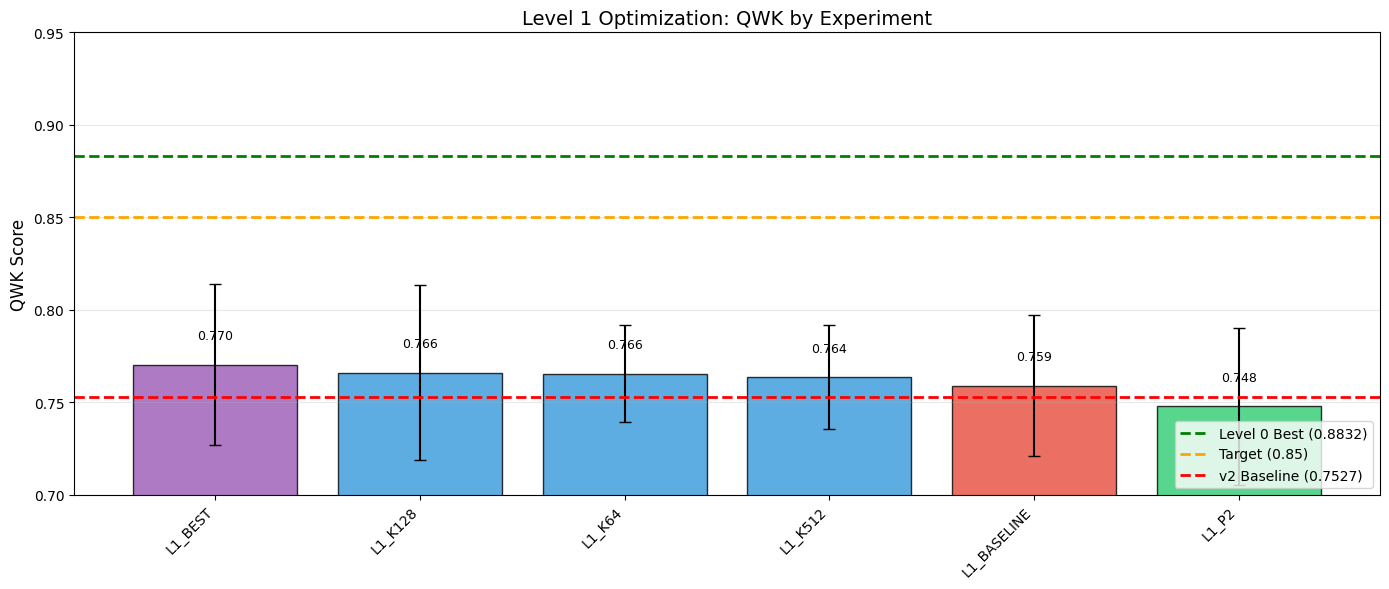

In [26]:
# 1. QWK by Experiment - Bar Chart
fig, ax = plt.subplots(figsize=(14, 6))

names = [name for name, _ in sorted_results]
means = [r['qwk']['mean'] for _, r in sorted_results]
stds = [r['qwk']['std'] for _, r in sorted_results]

# Color by phase
phase_colors = {1: '#3498db', 2: '#2ecc71', 3: '#9b59b6', 4: '#e74c3c'}
colors = [phase_colors.get(all_results[n].get('config', {}).get('phase', 1), '#95a5a6') for n in names]

bars = ax.bar(range(len(names)), means, yerr=stds, capsize=4, color=colors, alpha=0.8, edgecolor='black')

# Reference lines
ax.axhline(y=0.8832, color='green', linestyle='--', linewidth=2, label='Level 0 Best (0.8832)')
ax.axhline(y=0.85, color='orange', linestyle='--', linewidth=2, label='Target (0.85)')
ax.axhline(y=0.7527, color='red', linestyle='--', linewidth=2, label='v2 Baseline (0.7527)')

ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=45, ha='right')
ax.set_ylabel('QWK Score', fontsize=12)
ax.set_title('Level 1 Optimization: QWK by Experiment', fontsize=14)
ax.set_ylim(0.7, 0.95)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)

# Value labels
for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'qwk_by_experiment.png'), dpi=300, bbox_inches='tight')
plt.show()

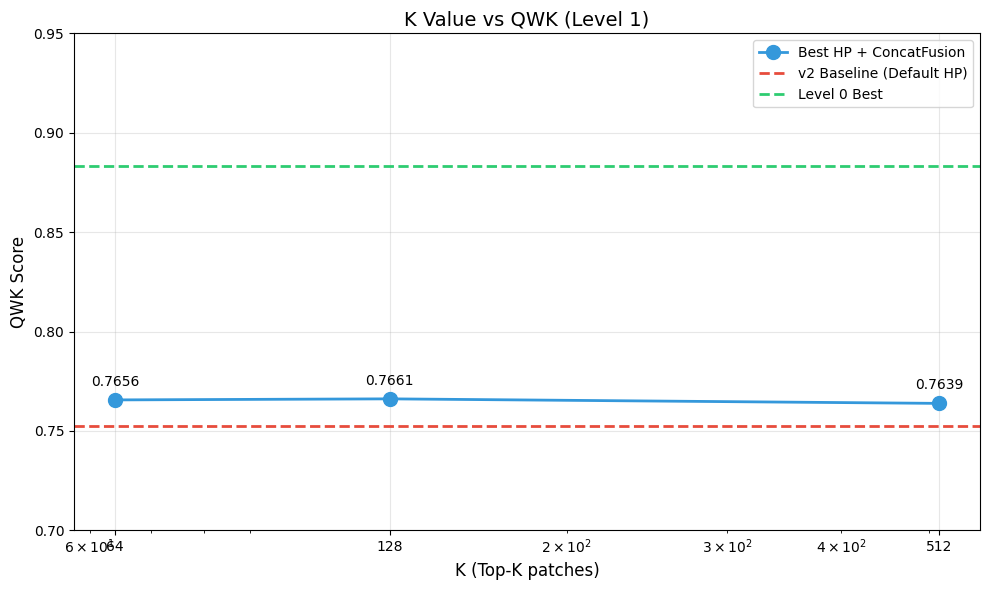

In [27]:
# 2. K Value vs QWK Line Plot
fig, ax = plt.subplots(figsize=(10, 6))

k_values = [64, 128, 512]
qwk_best_hp = [get_qwk('L1_K64'), get_qwk('L1_K128'), get_qwk('L1_K512')]
qwk_default_hp = [0.7527, 0.7527, 0.7527]  # Baseline reference (all use same HP)

ax.plot(k_values, qwk_best_hp, 'o-', color='#3498db', linewidth=2, markersize=10, label='Best HP + ConcatFusion')
ax.axhline(y=0.7527, color='#e74c3c', linestyle='--', linewidth=2, label='v2 Baseline (Default HP)')
ax.axhline(y=0.8832, color='#2ecc71', linestyle='--', linewidth=2, label='Level 0 Best')

for k, qwk in zip(k_values, qwk_best_hp):
    ax.annotate(f'{qwk:.4f}', (k, qwk), textcoords='offset points', xytext=(0, 10), ha='center')

ax.set_xlabel('K (Top-K patches)', fontsize=12)
ax.set_ylabel('QWK Score', fontsize=12)
ax.set_title('K Value vs QWK (Level 1)', fontsize=14)
ax.set_xscale('log')
ax.set_xticks(k_values)
ax.set_xticklabels([str(k) for k in k_values])
ax.set_ylim(0.7, 0.95)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'k_value_vs_qwk.png'), dpi=300, bbox_inches='tight')
plt.show()

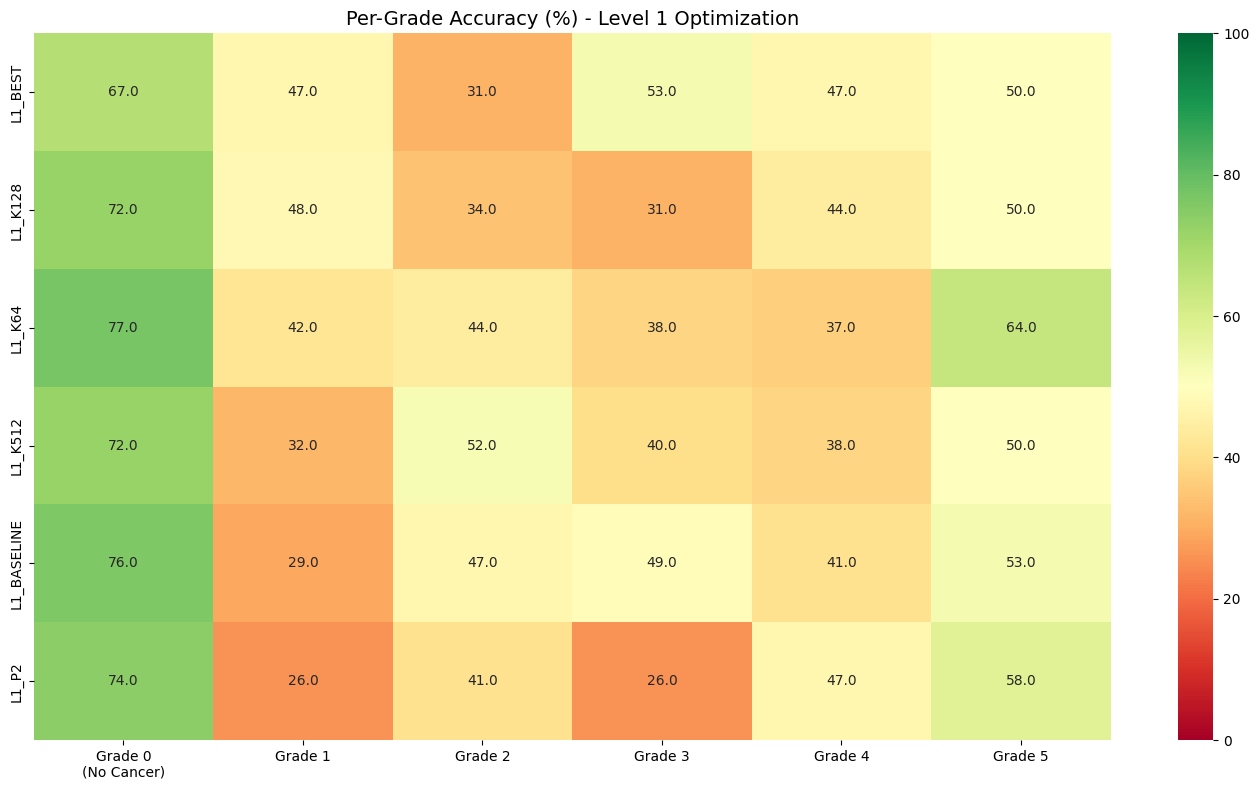

In [28]:
# 3. Per-Grade Accuracy Heatmap
fig, ax = plt.subplots(figsize=(14, 8))

models = [name for name, _ in sorted_results]
data = []
for name, r in sorted_results:
    row = [get_pga(r, g) * 100 for g in range(6)]
    data.append(row)

data = np.array(data)

sns.heatmap(data, annot=True, fmt='.1f', cmap='RdYlGn',
            xticklabels=['Grade 0\n(No Cancer)', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'],
            yticklabels=models, ax=ax, vmin=0, vmax=100)
ax.set_title('Per-Grade Accuracy (%) - Level 1 Optimization', fontsize=14)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'per_grade_accuracy_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()

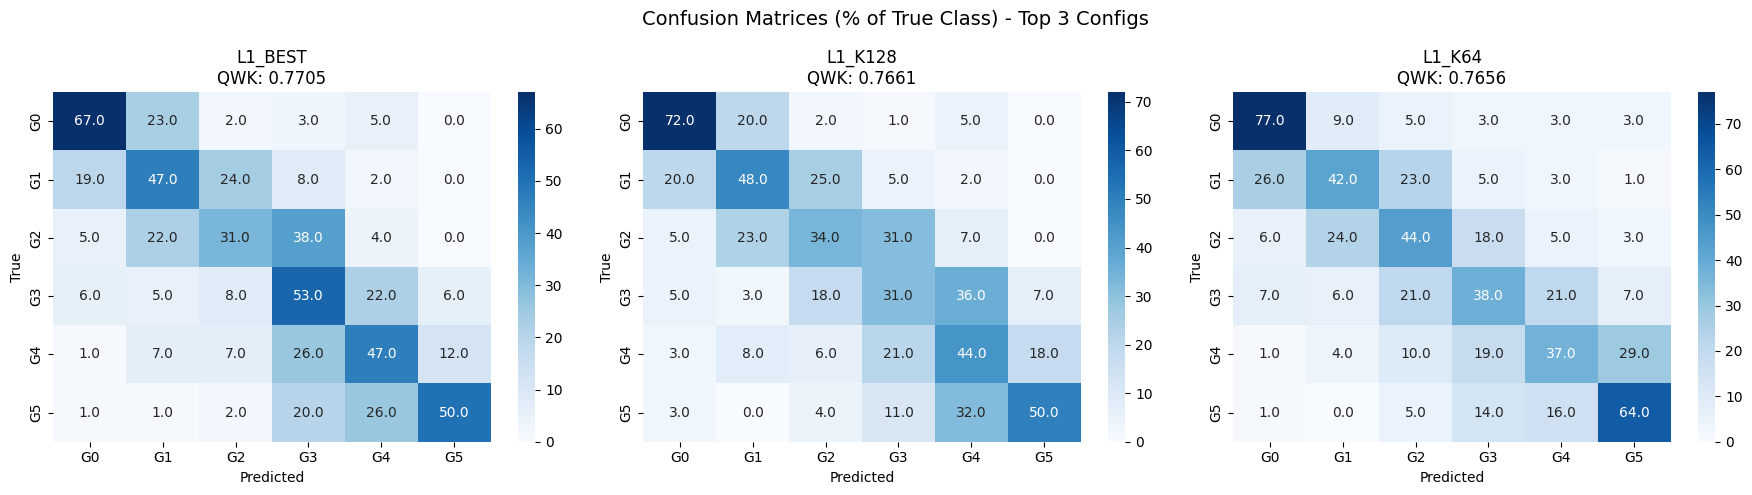

In [29]:
# 4. Confusion Matrix for Top 3 Configs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, r) in enumerate(sorted_results[:3]):
    cm = np.array(r['confusion_matrix'])
    cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100
    cm_normalized = np.nan_to_num(cm_normalized)

    sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues', ax=axes[i],
                xticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
                yticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'])
    axes[i].set_title(f'{name}\nQWK: {r["qwk"]["mean"]:.4f}', fontsize=12)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')

plt.suptitle('Confusion Matrices (% of True Class) - Top 3 Configs', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'confusion_matrices_top3.png'), dpi=300, bbox_inches='tight')
plt.show()

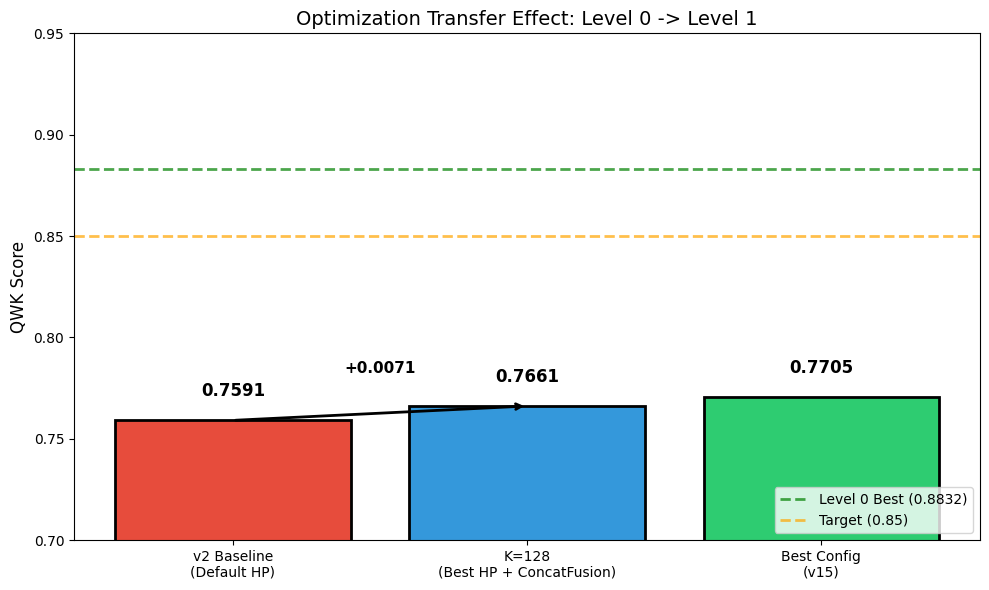

In [30]:
# 5. Optimization Transfer Effect Visualization
fig, ax = plt.subplots(figsize=(10, 6))

categories = ['v2 Baseline\n(Default HP)', 'K=128\n(Best HP + ConcatFusion)', 'Best Config\n(v15)']
values = [
    get_qwk('L1_BASELINE') if 'L1_BASELINE' in all_results else 0.7527,
    get_qwk('L1_K128'),
    max(r['qwk']['mean'] for r in all_results.values())
]

colors = ['#e74c3c', '#3498db', '#2ecc71']
bars = ax.bar(categories, values, color=colors, edgecolor='black', linewidth=2)

# Reference lines
ax.axhline(y=0.8832, color='green', linestyle='--', linewidth=2, alpha=0.7, label='Level 0 Best (0.8832)')
ax.axhline(y=0.85, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='Target (0.85)')

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Improvement arrows
if len(values) >= 2:
    improvement = values[1] - values[0]
    ax.annotate('', xy=(1, values[1]), xytext=(0, values[0]),
                arrowprops=dict(arrowstyle='->', color='black', lw=2))
    mid_x = 0.5
    mid_y = (values[0] + values[1]) / 2
    ax.text(mid_x, mid_y + 0.02, f'+{improvement:.4f}', ha='center', fontsize=11, fontweight='bold')

ax.set_ylabel('QWK Score', fontsize=12)
ax.set_title('Optimization Transfer Effect: Level 0 -> Level 1', fontsize=14)
ax.set_ylim(0.7, 0.95)
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'optimization_transfer_effect.png'), dpi=300, bbox_inches='tight')
plt.show()

## FINAL SUMMARY

In [31]:
# Final comprehensive summary
best_exp = sorted_results[0]
baseline_qwk = all_results.get('L1_BASELINE', {}).get('qwk', {}).get('mean', 0.7527)
level0_best = 0.8832

summary = {
    'experiment_version': 'v15_Level1_Optimization',
    'date': datetime.now().isoformat(),
    'total_experiments': len(all_results),

    'reference_results': {
        'level0_best': level0_best,
        'level1_v2_baseline': 0.7527,
        'original_gap': level0_best - 0.7527,
    },

    'best_result': {
        'experiment': best_exp[0],
        'description': best_exp[1]['description'],
        'qwk_mean': best_exp[1]['qwk']['mean'],
        'qwk_std': best_exp[1]['qwk']['std'],
        'grading_accuracy': best_exp[1]['grading_accuracy']['mean'],
        'binary_accuracy': best_exp[1]['binary_accuracy']['mean'],
        'macro_f1': best_exp[1]['macro_f1']['mean'],
        'config': best_exp[1].get('config', {}),
    },

    'improvements': {
        'vs_v2_baseline': best_exp[1]['qwk']['mean'] - baseline_qwk,
        'vs_v2_baseline_pct': (best_exp[1]['qwk']['mean'] - baseline_qwk) / baseline_qwk * 100,
        'gap_to_level0': best_exp[1]['qwk']['mean'] - level0_best,
    },

    'targets': {
        'qwk_target': 0.85,
        'qwk_achieved': best_exp[1]['qwk']['mean'],
        'target_met': best_exp[1]['qwk']['mean'] >= 0.85,
        'gap_target': 0.03,
        'gap_achieved': level0_best - best_exp[1]['qwk']['mean'],
        'gap_target_met': (level0_best - best_exp[1]['qwk']['mean']) <= 0.03,
    },

    'all_results_summary': {
        name: {
            'qwk': r['qwk']['mean'],
            'qwk_std': r['qwk']['std'],
            'config': r.get('config', {})
        }
        for name, r in all_results.items()
    }
}

# Save summary
with open(os.path.join(CONFIG['results_dir'], 'final_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=str)

# Print summary
print('\n' + '='*100)
print('FINAL SUMMARY: Level 1 (5x) Optimization v15')
print('='*100)

print(f'''
BEST MODEL: {best_exp[0]}
  Description: {best_exp[1]["description"]}

  METRICS:
    QWK:              {best_exp[1]["qwk"]["mean"]:.4f} +/- {best_exp[1]["qwk"]["std"]:.4f}
    Grading Accuracy: {best_exp[1]["grading_accuracy"]["mean"]*100:.2f}%
    Binary Accuracy:  {best_exp[1]["binary_accuracy"]["mean"]*100:.2f}%
    Macro F1:         {best_exp[1]["macro_f1"]["mean"]:.4f}

  PER-GRADE ACCURACY:
    Grade 0 (No Cancer): {get_pga(best_exp[1], 0)*100:.1f}%
    Grade 1:             {get_pga(best_exp[1], 1)*100:.1f}%
    Grade 2:             {get_pga(best_exp[1], 2)*100:.1f}%
    Grade 3:             {get_pga(best_exp[1], 3)*100:.1f}%
    Grade 4:             {get_pga(best_exp[1], 4)*100:.1f}%
    Grade 5:             {get_pga(best_exp[1], 5)*100:.1f}%

COMPARISON:
  Level 0 Best (20x):     {level0_best:.4f} QWK
  Level 1 v2 Baseline:    {baseline_qwk:.4f} QWK
  Level 1 v15 Best:       {best_exp[1]["qwk"]["mean"]:.4f} QWK

  Improvement vs v2:      {best_exp[1]["qwk"]["mean"] - baseline_qwk:+.4f} QWK ({(best_exp[1]["qwk"]["mean"] - baseline_qwk) / baseline_qwk * 100:+.1f}%)
  Gap to Level 0:         {best_exp[1]["qwk"]["mean"] - level0_best:+.4f} QWK

TARGETS:
  QWK >= 0.85:            {"ACHIEVED" if best_exp[1]["qwk"]["mean"] >= 0.85 else "NOT MET"} ({best_exp[1]["qwk"]["mean"]:.4f})
  Gap <= 0.03:            {"ACHIEVED" if (level0_best - best_exp[1]["qwk"]["mean"]) <= 0.03 else "NOT MET"} (gap: {level0_best - best_exp[1]["qwk"]["mean"]:.4f})
''')

# Decision Point
print('='*100)
print('DECISION POINT: NEXT STEPS')
print('='*100)

best_qwk = best_exp[1]['qwk']['mean']

if best_qwk >= 0.85:
    print('''
    TARGET ACHIEVED! QWK >= 0.85

    RECOMMENDED NEXT STEPS:
    ┌─────────────────────────────────────────────────────────────────────┐
    │  1. Proceed to Multi-Scale Fusion (v16)                            │
    │     - Combine Level 0 (20x) + Level 1 (5x) features                │
    │     - Expected: QWK > 0.90                                         │
    │                                                                     │
    │  2. Optional: Extract T192 features for PANDA comparison           │
    │     - Only if you want to validate against PANDA exact config      │
    └─────────────────────────────────────────────────────────────────────┘
    ''')
else:
    gap_to_target = 0.85 - best_qwk
    print(f'''
    TARGET NOT MET: QWK = {best_qwk:.4f} < 0.85 (need +{gap_to_target:.4f})

    RECOMMENDED NEXT STEPS:
    ┌─────────────────────────────────────────────────────────────────────┐
    │  STEP 1: Extract T192 features (PANDA-exact tile size)             │
    │          - Run preprocessing with uniform 192px tiles              │
    │          - Extract UNI features for T192 config                    │
    │                                                                     │
    │  STEP 2: Run L1_PANDA experiment                                   │
    │          - Config: T192 tiles + K=64 + Best HP + ConcatFusion      │
    │          - This matches PANDA 1st place exactly                    │
    │                                                                     │
    │  STEP 3: Compare results                                           │
    │          - If L1_PANDA > L1_BEST: Tile size matters for Level 1   │
    │          - If L1_PANDA <= L1_BEST: Issue is elsewhere              │
    │                                                                     │
    │  STEP 4: If still < 0.85, consider:                                │
    │          - Level 1-specific HP tuning                              │
    │          - Different K values for 5x magnification                 │
    │          - Increased training data                                  │
    └─────────────────────────────────────────────────────────────────────┘

    TO EXTRACT T192 FEATURES:
    Use CLAM_TR_v2_MultiScale.ipynb with config:
    - tile_size: 192 (uniform for all providers)
    - level: 1 (5x magnification)
    - Run: run_preprocessing_config('T192')
    - Run: run_feature_extraction_config('T192', 'uni')
    ''')

print('='*100)
print(f'Results saved to: {CONFIG["results_dir"]}')
print('\nFiles generated:')
print('  - all_results.json')
print('  - final_summary.json')
print('  - qwk_by_experiment.png')
print('  - k_value_vs_qwk.png')
print('  - per_grade_accuracy_heatmap.png')
print('  - confusion_matrices_top3.png')
print('  - optimization_transfer_effect.png')
print('\nDONE!')


FINAL SUMMARY: Level 1 (5x) Optimization v15

BEST MODEL: L1_BEST
  Description: Best config from Phase 1&2 + Best HP + ConcatFusion
  
  METRICS:
    QWK:              0.7705 +/- 0.0434
    Grading Accuracy: 49.17%
    Binary Accuracy:  89.17%
    Macro F1:         0.4874
  
  PER-GRADE ACCURACY:
    Grade 0 (No Cancer): 67.0%
    Grade 1:             47.0%
    Grade 2:             31.0%
    Grade 3:             53.0%
    Grade 4:             47.0%
    Grade 5:             50.0%

COMPARISON:
  Level 0 Best (20x):     0.8832 QWK
  Level 1 v2 Baseline:    0.7591 QWK
  Level 1 v15 Best:       0.7705 QWK
  
  Improvement vs v2:      +0.0114 QWK (+1.5%)
  Gap to Level 0:         -0.1127 QWK

TARGETS:
  QWK >= 0.85:            NOT MET (0.7705)
  Gap <= 0.03:            NOT MET (gap: 0.1127)

DECISION POINT: NEXT STEPS

    TARGET NOT MET: QWK = 0.7705 < 0.85 (need +0.0795)
    
    RECOMMENDED NEXT STEPS:
    ┌─────────────────────────────────────────────────────────────────────┐
    │  ST